# Notebook 01 — EDA & Data Preparation
## Marketing Incrementality & Causal Impact Study

**Dataset:** Hillstrom MineThatData E-Mail Analytics Challenge (synthetic replica)
- 64,000 customers; three-arm RCT: *No E-Mail / Mens E-Mail / Womens E-Mail*
- Outcomes measured 2 weeks post-campaign: **visit**, **conversion**, **spend**

**This notebook covers:**
1. Data loading & schema review
2. Treatment arm balance checks
3. Covariate distributions
4. Baseline outcome rates by arm
5. Feature engineering for downstream models
6. Save cleaned dataset

In [1]:
import sys, os
sys.path.insert(0, os.path.join(os.path.dirname(os.getcwd()), 'src'))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from generate_data import generate_hillstrom

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams.update({'figure.dpi': 120, 'axes.titlesize': 13})
pd.options.display.float_format = '{:,.3f}'.format

os.makedirs('../outputs', exist_ok=True)

Matplotlib is building the font cache; this may take a moment.


## 1. Load data

In [2]:
# Generate or load
csv_path = '../data/hillstrom.csv'
if not os.path.exists(csv_path):
    df_raw = generate_hillstrom()
    df_raw.to_csv(csv_path, index=False)
else:
    df_raw = pd.read_csv(csv_path)

print(f'Shape: {df_raw.shape}')
df_raw.head()

Shape: (64000, 12)


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,2,1) $0 - $100,59.480,1,1,Suburban,0,Web,No E-Mail,0,1,57.030
1,10,2) $100 - $200,143.480,0,1,Rural,0,Web,Womens E-Mail,0,1,61.760
2,8,2) $100 - $200,180.340,1,0,Urban,1,Web,Womens E-Mail,0,0,0.000
3,6,"6) $750 - $1,000",837.490,0,1,Urban,1,Web,Womens E-Mail,0,0,0.000
4,6,3) $200 - $350,278.630,1,0,Suburban,1,Multichannel,No E-Mail,0,0,0.000


In [3]:
df_raw.dtypes

recency              int64
history_segment        str
history            float64
mens                 int64
womens               int64
zip_code               str
newbie               int64
channel                str
segment                str
visit                int64
conversion           int64
spend              float64
dtype: object

In [4]:
df_raw.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
recency,"64,000.000",NaN,NaN,NaN,6.500,3.452,1.000,3.000,7.000,9.000,12.000
history_segment,64000,7,1) $0 - $100,16588,NaN,NaN,NaN,NaN,NaN,NaN,NaN
history,"64,000.000",NaN,NaN,NaN,326.633,312.512,0.000,85.572,231.730,436.962,"1,264.010"
mens,"64,000.000",NaN,NaN,NaN,0.622,0.485,0.000,0.000,1.000,1.000,1.000
womens,"64,000.000",NaN,NaN,NaN,0.626,0.484,0.000,0.000,1.000,1.000,1.000
zip_code,64000,3,Urban,27004,NaN,NaN,NaN,NaN,NaN,NaN,NaN
newbie,"64,000.000",NaN,NaN,NaN,0.318,0.466,0.000,0.000,0.000,1.000,1.000
channel,64000,3,Web,31924,NaN,NaN,NaN,NaN,NaN,NaN,NaN
segment,64000,3,Mens E-Mail,21535,NaN,NaN,NaN,NaN,NaN,NaN,NaN
visit,"64,000.000",NaN,NaN,NaN,0.118,0.323,0.000,0.000,0.000,0.000,1.000


## 2. Treatment arm balance
In a well-executed RCT, covariates should be balanced across arms. We check this with a **standardized mean difference (SMD)** — values < 0.10 indicate good balance.

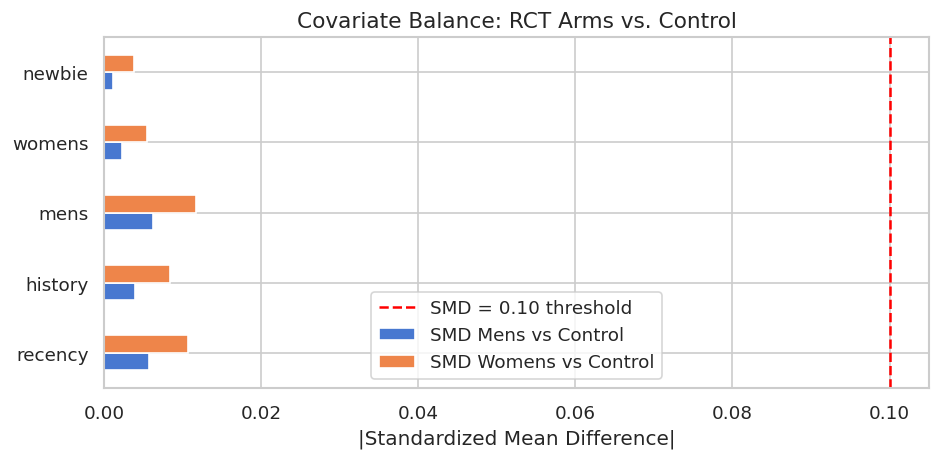

All SMDs < 0.10: True


In [5]:
def smd(a, b):
    """Standardized mean difference between two arrays."""
    pooled_std = np.sqrt((a.std()**2 + b.std()**2) / 2)
    return (a.mean() - b.mean()) / pooled_std if pooled_std > 0 else 0

num_features = ['recency', 'history', 'mens', 'womens', 'newbie']
control = df_raw[df_raw['segment'] == 'No E-Mail']
mens    = df_raw[df_raw['segment'] == 'Mens E-Mail']
womens  = df_raw[df_raw['segment'] == 'Womens E-Mail']

balance = pd.DataFrame({
    'SMD Mens vs Control':   [smd(mens[f], control[f]) for f in num_features],
    'SMD Womens vs Control': [smd(womens[f], control[f]) for f in num_features],
}, index=num_features)

fig, ax = plt.subplots(figsize=(8, 4))
balance.abs().plot(kind='barh', ax=ax)
ax.axvline(0.10, color='red', linestyle='--', label='SMD = 0.10 threshold')
ax.set_xlabel('|Standardized Mean Difference|')
ax.set_title('Covariate Balance: RCT Arms vs. Control')
ax.legend()
plt.tight_layout()
plt.savefig('../outputs/01_covariate_balance.png', bbox_inches='tight')
plt.show()
print('All SMDs < 0.10:', (balance.abs() < 0.10).all().all())

## 3. Covariate distributions

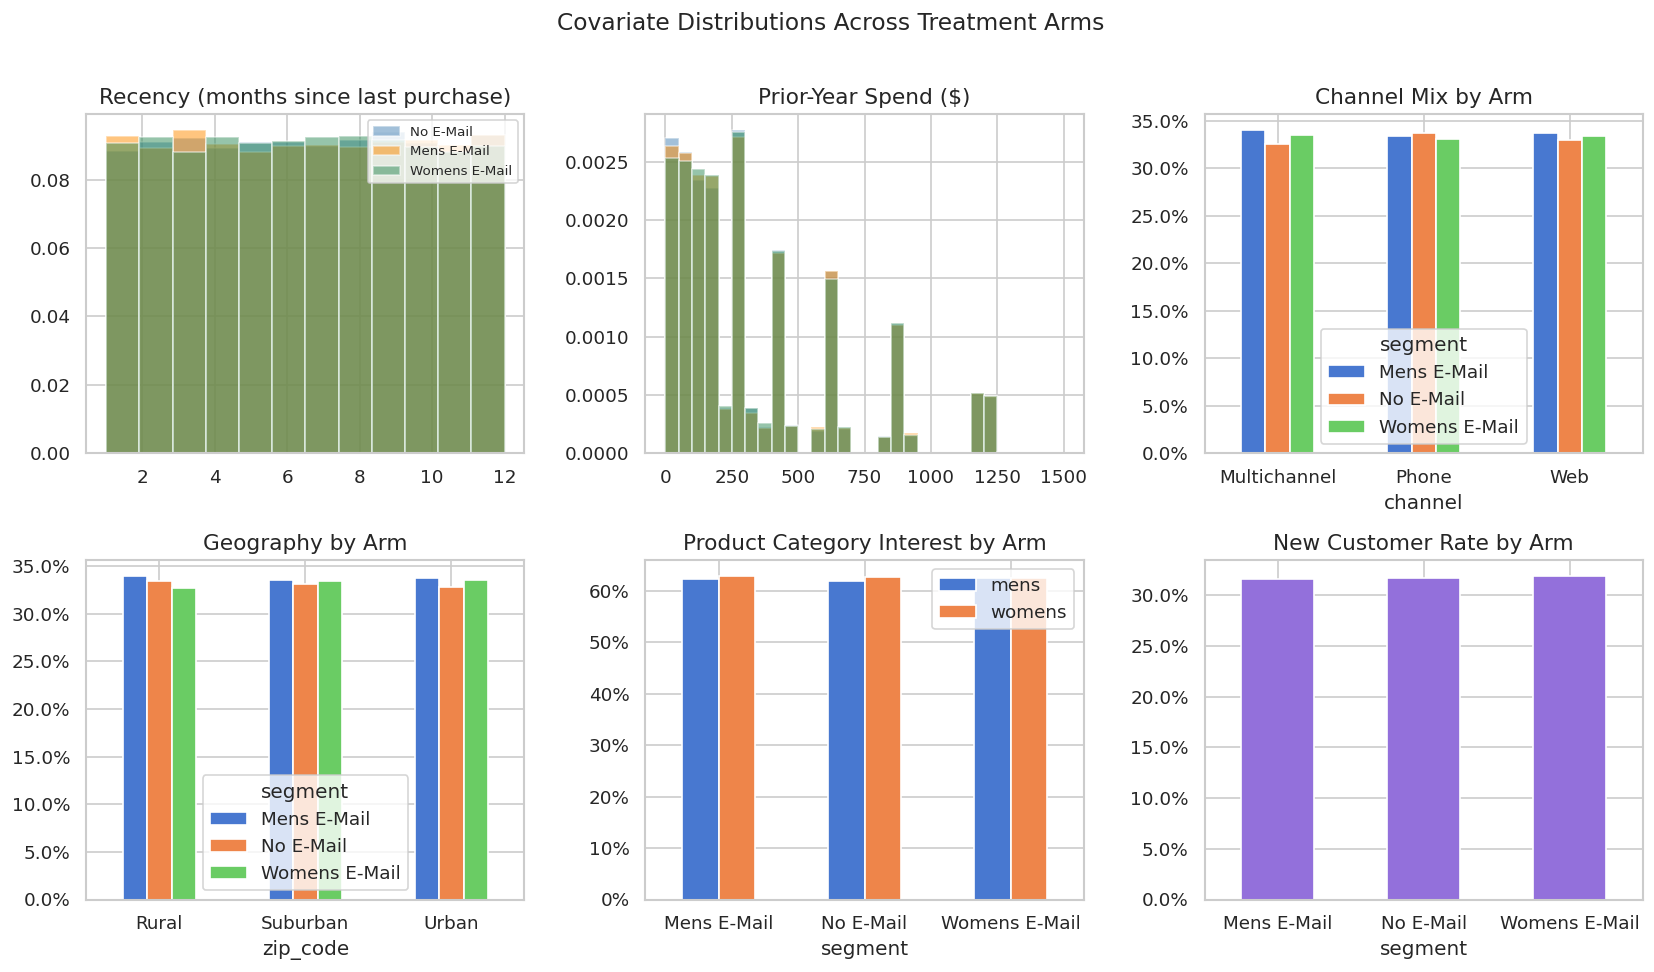

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

# Recency
for seg, color in [('No E-Mail','steelblue'),('Mens E-Mail','darkorange'),('Womens E-Mail','seagreen')]:
    axes[0].hist(df_raw.loc[df_raw.segment==seg,'recency'], bins=12, alpha=0.5, label=seg, color=color, density=True)
axes[0].set_title('Recency (months since last purchase)')
axes[0].legend(fontsize=8)

# History
for seg, color in [('No E-Mail','steelblue'),('Mens E-Mail','darkorange'),('Womens E-Mail','seagreen')]:
    axes[1].hist(df_raw.loc[df_raw.segment==seg,'history'], bins=30, alpha=0.5, label=seg, color=color, density=True, range=(0,1500))
axes[1].set_title('Prior-Year Spend ($)')

# Channel
ch_pct = df_raw.groupby(['channel','segment']).size().unstack(fill_value=0)
ch_pct = ch_pct.div(ch_pct.sum(axis=1), axis=0)
ch_pct.plot(kind='bar', ax=axes[2], rot=0)
axes[2].set_title('Channel Mix by Arm')
axes[2].yaxis.set_major_formatter(mtick.PercentFormatter(1))

# Zip code
zip_pct = df_raw.groupby(['zip_code','segment']).size().unstack(fill_value=0)
zip_pct = zip_pct.div(zip_pct.sum(axis=1), axis=0)
zip_pct.plot(kind='bar', ax=axes[3], rot=0)
axes[3].set_title('Geography by Arm')
axes[3].yaxis.set_major_formatter(mtick.PercentFormatter(1))

# Mens / Womens product flag
prod = df_raw.groupby('segment')[['mens','womens']].mean()
prod.plot(kind='bar', ax=axes[4], rot=0)
axes[4].set_title('Product Category Interest by Arm')
axes[4].yaxis.set_major_formatter(mtick.PercentFormatter(1))

# Newbie
new_pct = df_raw.groupby('segment')['newbie'].mean()
new_pct.plot(kind='bar', ax=axes[5], rot=0, color='mediumpurple')
axes[5].set_title('New Customer Rate by Arm')
axes[5].yaxis.set_major_formatter(mtick.PercentFormatter(1))

plt.suptitle('Covariate Distributions Across Treatment Arms', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('../outputs/01_covariate_distributions.png', bbox_inches='tight')
plt.show()

## 4. Baseline outcome rates by arm

=== Outcome Summary by Arm ===
              visit              conversion              spend             \
               mean   sum  count       mean   sum  count  mean        sum   
segment                                                                     
Mens E-Mail   0.134  2875  21535      0.061  1309  21535 3.387 72,947.810   
No E-Mail     0.078  1640  21152      0.048  1023  21152 2.442 51,647.580   
Womens E-Mail 0.143  3047  21313      0.064  1359  21313 3.571 76,099.710   

                      
               count  
segment               
Mens E-Mail    21535  
No E-Mail      21152  
Womens E-Mail  21313  


/tmp/ipykernel_499/1196654074.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(vals.index, rotation=15, ha='right', fontsize=9)
/tmp/ipykernel_499/1196654074.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(vals.index, rotation=15, ha='right', fontsize=9)
/tmp/ipykernel_499/1196654074.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(vals.index, rotation=15, ha='right', fontsize=9)


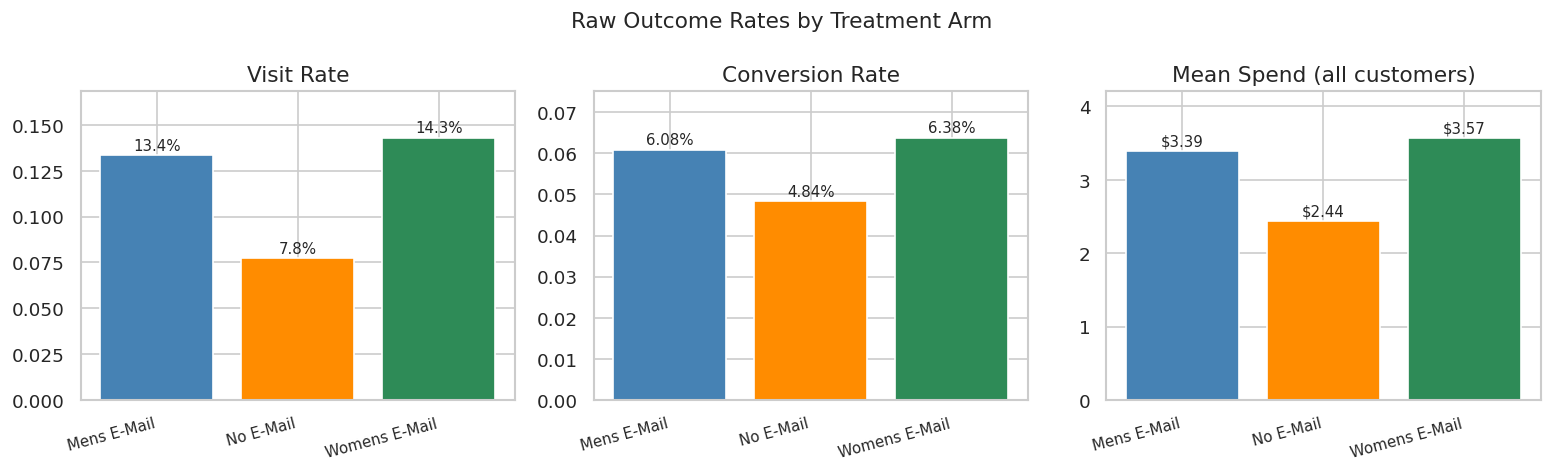

In [7]:
outcomes = df_raw.groupby('segment')[['visit','conversion','spend']].agg(['mean','sum','count'])
print('=== Outcome Summary by Arm ===')
print(outcomes)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col, label, fmt in zip(
    axes,
    ['visit','conversion','spend'],
    ['Visit Rate','Conversion Rate','Mean Spend (all customers)'],
    ['{:.1%}', '{:.2%}', '${:.2f}']
):
    vals = df_raw.groupby('segment')[col].mean()
    bars = ax.bar(vals.index, vals.values, color=['steelblue','darkorange','seagreen'])
    ax.set_title(label)
    ax.set_xticklabels(vals.index, rotation=15, ha='right', fontsize=9)
    for bar, v in zip(bars, vals.values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height()*1.01,
                fmt.format(v), ha='center', va='bottom', fontsize=9)
    ax.set_ylim(0, vals.max() * 1.18)

plt.suptitle('Raw Outcome Rates by Treatment Arm', fontsize=13)
plt.tight_layout()
plt.savefig('../outputs/01_raw_outcomes.png', bbox_inches='tight')
plt.show()

## 5. Feature engineering

In [8]:
df = df_raw.copy()

# Encode categoricals
df['channel_web']   = (df['channel'] == 'Web').astype(int)
df['channel_multi'] = (df['channel'] == 'Multichannel').astype(int)
df['zip_urban']     = (df['zip_code'] == 'Urban').astype(int)
df['zip_suburban']  = (df['zip_code'] == 'Suburban').astype(int)

# Log-transform history (right-skewed)
df['log_history'] = np.log1p(df['history'])

# Treatment indicators
df['treated']        = (df['segment'] != 'No E-Mail').astype(int)
df['treatment_mens'] = (df['segment'] == 'Mens E-Mail').astype(int)
df['treatment_womens'] = (df['segment'] == 'Womens E-Mail').astype(int)

FEATURE_COLS = ['recency', 'log_history', 'mens', 'womens', 'newbie',
                'channel_web', 'channel_multi', 'zip_urban', 'zip_suburban']

df.to_csv('../data/hillstrom_clean.csv', index=False)
print('Saved cleaned dataset.')
df[FEATURE_COLS + ['treated','treatment_mens','treatment_womens','visit','conversion','spend']].head()

Saved cleaned dataset.


,recency,log_history,mens,womens,newbie,channel_web,channel_multi,zip_urban,zip_suburban,treated,treatment_mens,treatment_womens,visit,conversion,spend
0,2,4.102,1,1,0,1,0,0,1,0,0,0,0,1,57.030
1,10,4.973,0,1,0,1,0,0,0,1,0,1,0,1,61.760
2,8,5.200,1,0,1,1,0,1,0,1,0,1,0,0,0.000
3,6,6.732,0,1,1,1,0,1,0,1,0,1,0,0,0.000
4,6,5.633,1,0,1,0,1,0,1,0,0,0,0,0,0.000
